# Day 36 | Give a Model a Small Python Tool

**KGP Talkie**

Define a tool name, description, input schema, and result.

Run from top to bottom with the **KGP Talkie (course)** kernel. Each notebook starts its own small example. Use the handout for the idea, then inspect the real outputs here.

Imports first. Path handles file paths; os reads a setting from the environment.

In [1]:
from pathlib import Path
import os

Open this notebook from its notebooks folder. Its assets folder is one level above.

In [2]:
BASE = Path.cwd().parent
ASSETS = BASE / "assets"

Our generated files go into a separate outputs folder, so sample inputs stay unchanged.

In [3]:
OUTPUT = BASE / "outputs"
OUTPUT.mkdir(exist_ok=True)

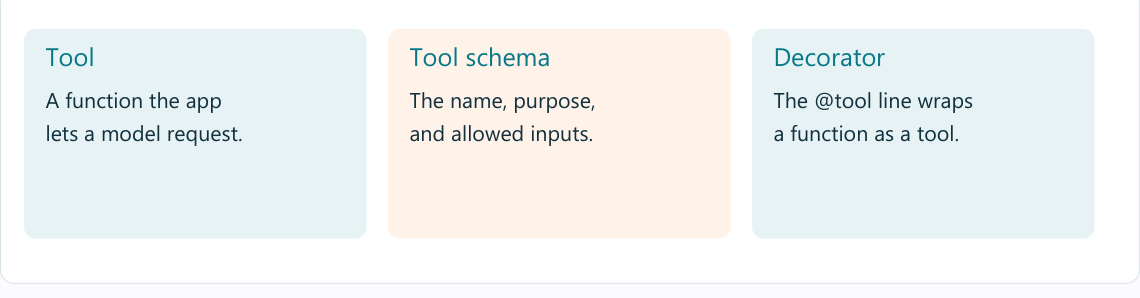

@tool wraps a documented function and exposes its input types as a tool schema.

In [4]:
from langchain_core.tools import tool

The model sees a name, description, and two integer inputs. Python computes the sum.

In [5]:
@tool
def add_numbers(a: int, b: int) -> int:
    """Add two integer numbers and return their exact sum."""
    return a + b

In [6]:
@tool
def multiply(a: int, b: int) -> int:
    """Multiply two integer numbers and return their exact product."""
    return a * b

In [7]:
print(add_numbers.name)
print(add_numbers.args)

add_numbers
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}


Test the function directly before a model is allowed to request it.

In [8]:
add_numbers.invoke({"a": 7, "b": 5})

12

In [9]:
multiply.invoke({"a": 6, "b": 7})

42

A fresh input checks the tool beyond the first positive-number example.

In [10]:
add_numbers.invoke({"a": -2, "b": 9})

7

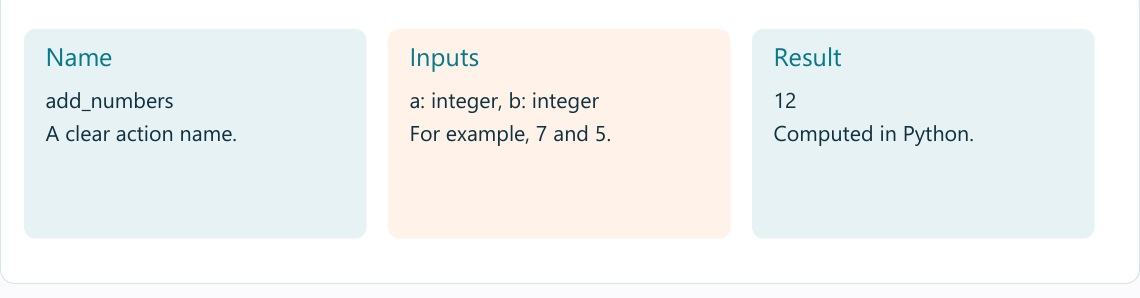

## Try a fresh input

Try different integers and a wrong input type. Check which values the schema accepts.

Compare the real output with the given input. A neat format is not proof of correct facts.

## Complete KGP Talkie tutorial

Read the complete tutorial breakdown for this section in our [KGP Talkie article](https://kgptalkie.com/tutorials/generative-ai/langchain-tool-calling).